# 02 — Measure target (Far Red-640) intensity per cell

Reads the segmentation manifest from notebook 01 (one row per **point**, i.e. per field of view -- a single ND2 file can contribute many rows), extracts the Far Red - 640 target channel for that exact point, and measures per-cell mean/max/integrated intensity against the instance masks from notebook 01 -- with cells touching the frame edge excluded first (`exclude_border`, see `config.yaml`), since an incompletely-imaged cell would bias its own MFI. This is the project-specific half of the pipeline -- segmentation never has to change for this or any future analysis built on the same manifest.

In [2]:
import pandas as pd
from tqdm.auto import tqdm

from cell_tracker import (
    load_config, load_nd2_point, extract_channels, load_segmentation,
    background_subtract, compute_segmentation_background,
    measure_intensity_per_cell,
)

cfg = load_config('../config.yaml')
manifest_full = pd.read_csv(cfg['paths']['segmentation_work_dir'] / 'manifest.csv')

if 'excluded' in manifest_full.columns:
    n_excluded = int(manifest_full['excluded'].sum())
    if n_excluded:
        print(f'Skipping {n_excluded} excluded point(s) (see notebook 01\'s Excluded frames section for why):')
        print(manifest_full.loc[manifest_full['excluded'], 'point_label'].tolist())
    manifest = manifest_full[~manifest_full['excluded']].reset_index(drop=True)
else:
    manifest = manifest_full

# manifest_full (unfiltered) is kept around so a background reference point
# can still be found even if it happened to be flagged excluded elsewhere.

bg_cfg = cfg.get('background_subtraction', {})
exclude_border = cfg.get('exclude_border', False)
print(f'exclude_border = {exclude_border} (cells touching the frame edge will be '
      f'{"dropped" if exclude_border else "kept"} before measurement)')
manifest[['replicate', 'condition', 'filename', 'point_label', 'n_cells']] if 'n_cells' in manifest else manifest.head()

exclude_border = False (cells touching the frame edge will be kept before measurement)


,replicate,condition,filename,point_label,n_cells
0,20260812,KO IgG,"WellB06_ChannelGreen - 488,Far Red - 640_Seq00...",B06_0000,393
1,20260812,KO IgG,"WellB06_ChannelGreen - 488,Far Red - 640_Seq00...",B06_0001,434
2,20260812,KO IgG,"WellB06_ChannelGreen - 488,Far Red - 640_Seq00...",B06_0002,400
3,20260812,KO IgG,"WellB06_ChannelGreen - 488,Far Red - 640_Seq00...",B06_0003,467
4,20260812,KO IgG,"WellB06_ChannelGreen - 488,Far Red - 640_Seq00...",B06_0004,240
...,...,...,...,...,...
315,20260817,NT blank,"WellE02_ChannelGreen - 488,Far Red - 640_Seq00...",E02_0015,244
316,20260817,NT blank,"WellE02_ChannelGreen - 488,Far Red - 640_Seq00...",E02_0016,185
317,20260817,NT blank,"WellE02_ChannelGreen - 488,Far Red - 640_Seq00...",E02_0017,187
318,20260817,NT blank,"WellE02_ChannelGreen - 488,Far Red - 640_Seq00...",E02_0018,63


## Background subtraction

`background_subtraction.method: segmentation_background` (`config.yaml`) computes ONE background value per replicate -- the mean Far Red-640 intensity across every pixel in a single, manually chosen reference point (`reference_points` in `config.yaml`) that is NOT covered by any segmented cell. That one value is subtracted from every point in the same replicate (clipped at 0) before per-cell intensity is measured below. Update `reference_points` in `config.yaml` -- one `{condition, point_index}` entry per real replicate -- to pick whichever point best represents real background in that replicate.

In [3]:
target_cfg = {'target': cfg['target_channel']}

background_by_replicate = {}
if bg_cfg.get('enabled') and bg_cfg.get('method') == 'segmentation_background':
    reference_points = bg_cfg.get('reference_points', {})
    if not reference_points:
        raise ValueError(
            "background_subtraction.method is 'segmentation_background' but config.yaml has "
            "no reference_points defined -- add one {condition, point_index} entry per replicate."
        )
    for replicate, ref in reference_points.items():
        match = manifest_full[
            (manifest_full['replicate'].astype(str) == str(replicate))
            & (manifest_full['condition'] == ref['condition'])
            & (manifest_full['point_index'] == ref['point_index'])
        ]
        if match.empty:
            raise ValueError(
                f"No manifest row found for background reference point: replicate={replicate!r}, "
                f"condition={ref['condition']!r}, point_index={ref['point_index']!r}. Check "
                f"config.yaml's reference_points against notebook 01's manifest."
            )
        ref_row = match.iloc[0]
        ref_sub_arr, ref_channel_meta = load_nd2_point(ref_row['nd2_path'], ref_row['point_index'])
        ref_target_img = extract_channels(ref_sub_arr, ref_channel_meta, target_cfg, cfg.get('zstack'))['target']
        ref_label_img = load_segmentation(ref_row['segmentation_path'])
        bg_value = compute_segmentation_background(ref_label_img, ref_target_img)
        background_by_replicate[replicate] = bg_value
        print(f"Replicate {replicate!r} background (from {ref['condition']!r} "
              f"point_index={ref['point_index']}, point_label={ref_row['point_label']}): {bg_value:.2f}")
else:
    print('Segmentation-based background subtraction not active '
          '(check background_subtraction.enabled / method in config.yaml).')

Replicate 20260812 background (from 'KO IgG' point_index=12, point_label=B06_0012): 407.56
Replicate 20260813 background (from 'KO IgG' point_index=11, point_label=C06_0011): 408.14
Replicate 20260814 background (from 'KO IgG' point_index=5, point_label=D06_0005): 408.80
Replicate 20260817 background (from 'KO IgG' point_index=2, point_label=E06_0002): 406.17


In [4]:
per_image_results = []
for row in tqdm(manifest.itertuples(), total=len(manifest), desc='Measuring target intensity'):
    # load_nd2_point re-opens just this row's specific point (field of
    # view) within its ND2 file -- correct even when a file has many points.
    sub_arr, channel_meta = load_nd2_point(row.nd2_path, row.point_index)
    target_img = extract_channels(sub_arr, channel_meta, target_cfg, cfg.get('zstack'))['target']

    if bg_cfg.get('enabled'):
        if bg_cfg.get('method') == 'segmentation_background':
            target_img = background_subtract(target_img, method='fixed', value=background_by_replicate[row.replicate])
        else:
            target_img = background_subtract(target_img, method=bg_cfg.get('method', 'median'))

    label_img = load_segmentation(row.segmentation_path)

    df = measure_intensity_per_cell(
        label_img, target_img, channel_name='647',
        exclude_border=exclude_border,
        source_file=row.filename, point_label=row.point_label,
        replicate=row.replicate, condition=row.condition,
    )
    per_image_results.append(df)

print(f'Measured {len(per_image_results)} point(s), '
      f'{sum(len(d) for d in per_image_results)} cell(s) total '
      f'(edge-touching cells already excluded).')

Measuring target intensity:   0%|          | 0/320 [00:00<?, ?it/s]

Measured 320 point(s), 105318 cell(s) total (edge-touching cells already excluded).


In [5]:
import numpy as np

# Concatenate every point's per-cell rows in memory ONLY -- per-cell data is
# an intermediate for the well/replicate averages below, not saved as its
# own file./
master = pd.concat(per_image_results, ignore_index=True)
print(f'{len(master)} cell(s) measured across {master[["replicate", "condition", "point_label"]].drop_duplicates().shape[0]} point(s).')

105318 cell(s) measured across 320 point(s).


## MFI summary (single output file)

`data/results/mfi_summary.csv` -- everything in one file:

- **Well-level columns** (`replicate`, then one column per condition): each
  value is one point's overall 647 MFI = (total background-subtracted 647
  fluorescence summed across every segmented cell in that point) / (total
  segmented-cell area in that point) -- pixel-weighted across all cells in
  the field of view, not a plain average of per-cell means. 80 rows per
  condition, grouped by replicate (20 per replicate here), in the order
  given by the shared `replicate` column.
- **Replicate-average columns** (`replicate_avg_label`, then
  `<condition>_replicate_avg`): the plain arithmetic mean of that
  replicate's 20 well-level values for that condition -- one row per
  replicate (4 rows), blank after. `replicate_avg_label` says which
  replicate each of those 4 rows is.

In [6]:
point_group_cols = ['replicate', 'condition', 'point_label']
per_point = (
    master.groupby(point_group_cols)
    .agg(total_integrated_647=('integrated_intensity_647', 'sum'),
         total_area_px=('area_px', 'sum'))
    .reset_index()
)
per_point['point_mfi_647'] = np.where(
    per_point['total_area_px'] > 0,
    per_point['total_integrated_647'] / per_point['total_area_px'],
    np.nan,
)

conditions = sorted(per_point['condition'].unique())
replicates = sorted(per_point['replicate'].unique())

# --- Well-level block: one row per point, grouped by replicate, one column
# per condition. All conditions share a 'replicate' label column, which
# only lines up cleanly if every replicate contributes the same number of
# points to every condition (true for this dataset -- 20 each); a warning
# prints if that's ever not the case, rather than silently misaligning.
well_rows = []
for replicate in replicates:
    sub = per_point[per_point['replicate'] == replicate]
    counts = sub.groupby('condition').size()
    if counts.nunique() > 1:
        print(f'WARNING: replicate {replicate!r} has uneven point counts per condition: '
              f'{counts.to_dict()} -- well-level rows below will be padded with blanks, '
              f'not misaligned.')
    per_cond_series = {
        cond: sub.loc[sub['condition'] == cond].sort_values('point_label')['point_mfi_647'].reset_index(drop=True)
        for cond in conditions
    }
    n_rows = max(len(s) for s in per_cond_series.values())
    for i in range(n_rows):
        row = {'replicate': replicate}
        for cond in conditions:
            s = per_cond_series[cond]
            row[cond] = s[i] if i < len(s) else np.nan
        well_rows.append(row)
well_df = pd.DataFrame(well_rows)

# --- Replicate-average block: plain mean of each replicate's well-level
# values per condition -- one row per replicate.
replicate_avg_rows = []
for replicate in replicates:
    row = {'replicate_avg_label': replicate}
    for cond in conditions:
        vals = per_point.loc[
            (per_point['replicate'] == replicate) & (per_point['condition'] == cond), 'point_mfi_647'
        ]
        row[f'{cond}_replicate_avg'] = vals.mean() if len(vals) else np.nan
    replicate_avg_rows.append(row)
replicate_avg_df = pd.DataFrame(replicate_avg_rows)

# Side by side in one file -- replicate_avg_df is shorter (one row per
# replicate), pandas pads the rest with blanks automatically.
combined = pd.concat([well_df, replicate_avg_df], axis=1)
summary_path = cfg['paths']['results_dir'] / 'mfi_summary.csv'
combined.to_csv(summary_path, index=False)

print(f'MFI summary -> {summary_path}')
print(f'{len(well_df)} well-level row(s), {len(replicate_avg_df)} replicate-average row(s).')
combined

MFI summary -> /Users/andrewmanion/Documents/python pipelines/Erika small beads/data/results/mfi_summary.csv
80 well-level row(s), 4 replicate-average row(s).


,replicate,KO IgG,KO blank,NT IgG,NT blank,replicate_avg_label,KO IgG_replicate_avg,KO blank_replicate_avg,NT IgG_replicate_avg,NT blank_replicate_avg
0,20260812,435.641580,212.030117,363.092487,52.164643,20260812.0,335.003442,49.600588,291.658624,38.220021
1,20260812,208.269963,86.539509,437.311377,25.747996,20260813.0,97.245203,18.068900,90.709727,14.293506
2,20260812,366.999974,22.337585,276.266223,61.713134,20260814.0,249.921300,17.612092,191.436731,27.554383
3,20260812,307.790369,26.200673,450.144136,182.220382,20260817.0,215.352419,36.102388,170.268554,47.753630
4,20260812,357.367925,20.584730,351.371017,21.012607,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
75,20260817,134.582812,42.734935,146.990511,59.585036,NaN,NaN,NaN,NaN,NaN
76,20260817,222.788026,33.251974,159.031352,46.670622,NaN,NaN,NaN,NaN,NaN
77,20260817,240.231560,35.262479,217.879129,65.951255,NaN,NaN,NaN,NaN,NaN
78,20260817,215.670262,33.447342,247.062764,107.348203,NaN,NaN,NaN,NaN,NaN


## Quick look at the distribution

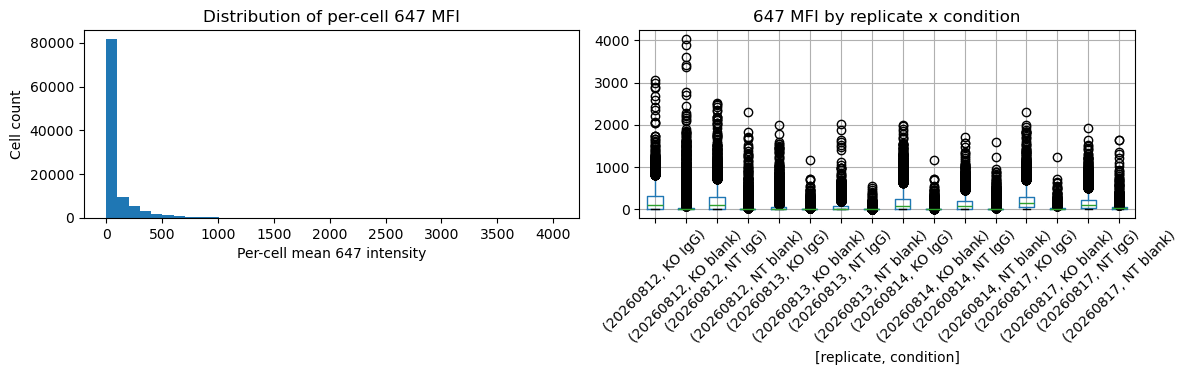

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(master['mean_intensity_647'], bins=40)
axes[0].set_xlabel('Per-cell mean 647 intensity')
axes[0].set_ylabel('Cell count')
axes[0].set_title('Distribution of per-cell 647 MFI')

master.boxplot(column='mean_intensity_647', by=['replicate', 'condition'], ax=axes[1], rot=45)
axes[1].set_title('647 MFI by replicate x condition')
plt.suptitle('')
fig.tight_layout()
plt.show()

## Notes

- Background subtraction uses `segmentation_background` (see the Background subtraction section above) -- one value per replicate, computed from a manually chosen reference point's non-cell area, subtracted from every point in that replicate before any MFI in `mfi_summary.csv` is computed.
- `mfi_summary.csv` is the only saved output now -- per-cell results are computed in memory (`master`, used for the histogram below) but not written to disk; see the MFI summary section above for exactly how the well-level and replicate-average columns are computed.
- Cross-check `data/qc/*_qc.png` panels against these numbers before drawing conclusions -- bad segmentation silently produces bad MFI values. This classifier is reused from a different dataset/channel (see `green` panel README), so this check matters more here than for a same-channel project. Only the first point per run got a QC panel by default (`qc_first_only` in `config.yaml`); re-run notebook 01 with `qc_first_only: false` if you want to eyeball more.
- Cells touching the frame edge were dropped before these numbers were computed (`exclude_border: true` in `config.yaml`) -- an incompletely-imaged cell would otherwise bias its own MFI.
- Remember this ran against whatever `use_test_data` was set to in notebook 01 (`config.yaml`) -- check the manifest's `replicate`/`condition` columns (they'll read `test`/`test` for a test run) before trusting these as real results.
- To add more analysis (extra channels, morphology, ratios), add a new notebook that reads `data/segmentation_work/manifest.csv` and reuses `load_nd2_point` + `load_segmentation` + `measure_intensity_per_cell` the same way this notebook does -- no need to re-run segmentation.